In [1]:
from requirements import *

# Figure 1

In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)
adata_cite = sc.read_h5ad(CITE)

## Figure 1b. Xenium single-cell spatial cell-type UMAP


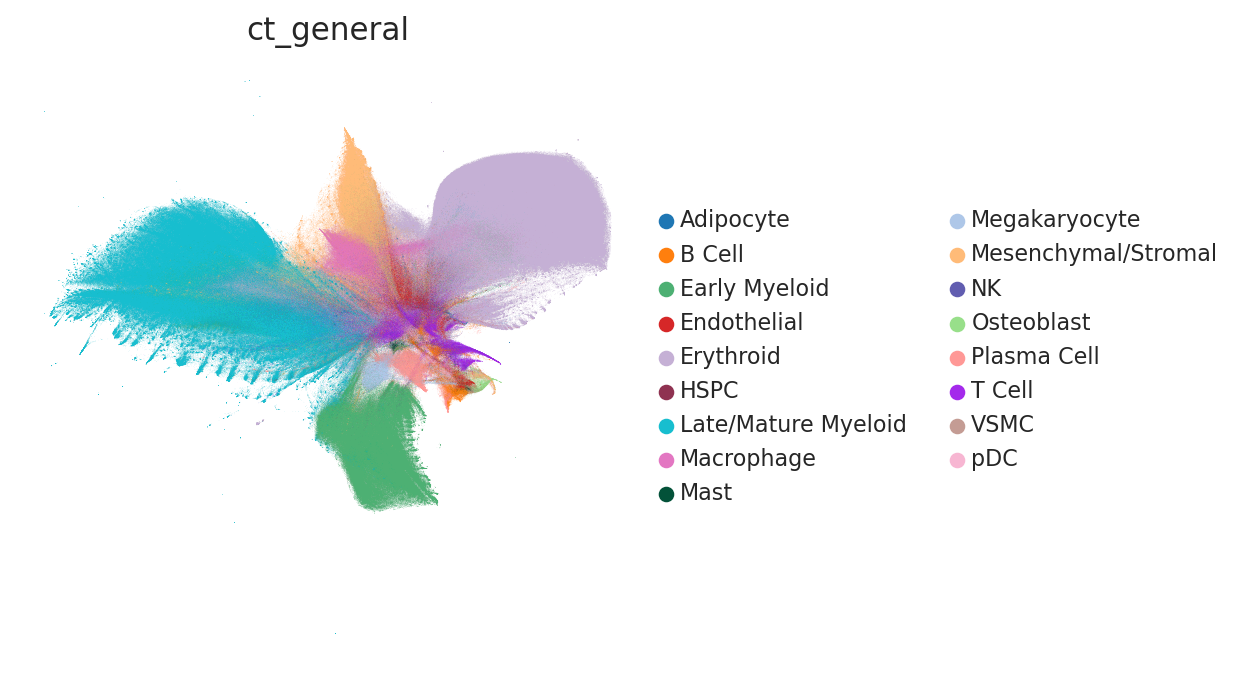

In [3]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.umap(
    adata_xenv1, 
    color=['ct_general'], 
    frameon=False,
    wspace=0.6, ncols=2,vmin = 0, vmax = 3, sort_order = True, size = 0.07,
    legend_fontsize =10, palette={ "T Cell":"#a42aeb", "B Cell": "#ff7f0e", "NK": "#ffffff", "Plasma Cell": "#ff9896", 
         "Early Myeloid": "#4db073", "Late/Mature Myeloid": "#17becf", "Macrophage": "#e377c2", "Mast": "#035239",
         "pDC": "#f7b6d2", "Megakaryocyte": "#aec7e8",
        "Adipocyte": "#1f77b4", "VSMC": "#c49c94", "Mesenchymal/Stromal": "#ffbb78", 
         "Osteoblast": "#98df8a",
         "Endothelial": "#d62728", 
         "Erythroid":"#c5b0d5", "HSPC": '#8f3251', "NK": '#615db0'} 
)


## Figure 1b. CITE-seq scRNA+scProtein+scTCR cell-type 


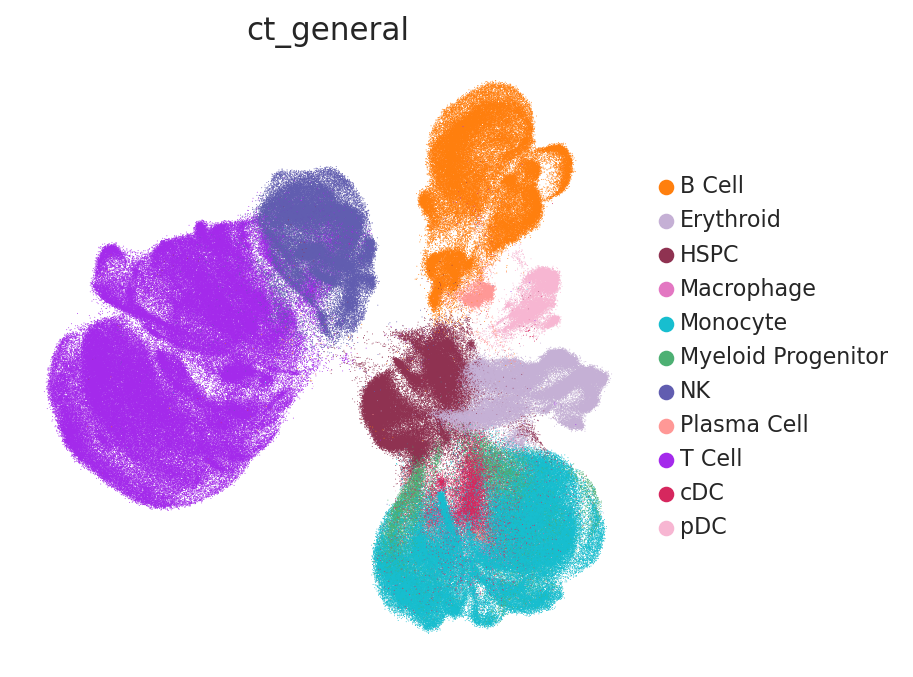

In [4]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.umap(
    adata_cite, 
    color=['ct_general'], 
    frameon=False,
    wspace=0.6, ncols=2,vmin = 0, vmax = 3, sort_order = True, size = 0.7,
    legend_fontsize =10,  palette={ "T Cell":"#a42aeb", "B Cell": "#ff7f0e", "NK": '#615db0', "Plasma Cell": "#ff9896", 
         "Myeloid Progenitor": "#4db073", "Monocyte": "#17becf", "Macrophage": "#e377c2", 
         "pDC": "#f7b6d2", 'cDC': "#d6275e",  
         "Erythroid":"#c5b0d5", "HSPC": '#8f3251'}, 
)


## Figure 1c. Cell-type frequency within diagnosis group (stacked bar)


<Figure size 480x320 with 0 Axes>

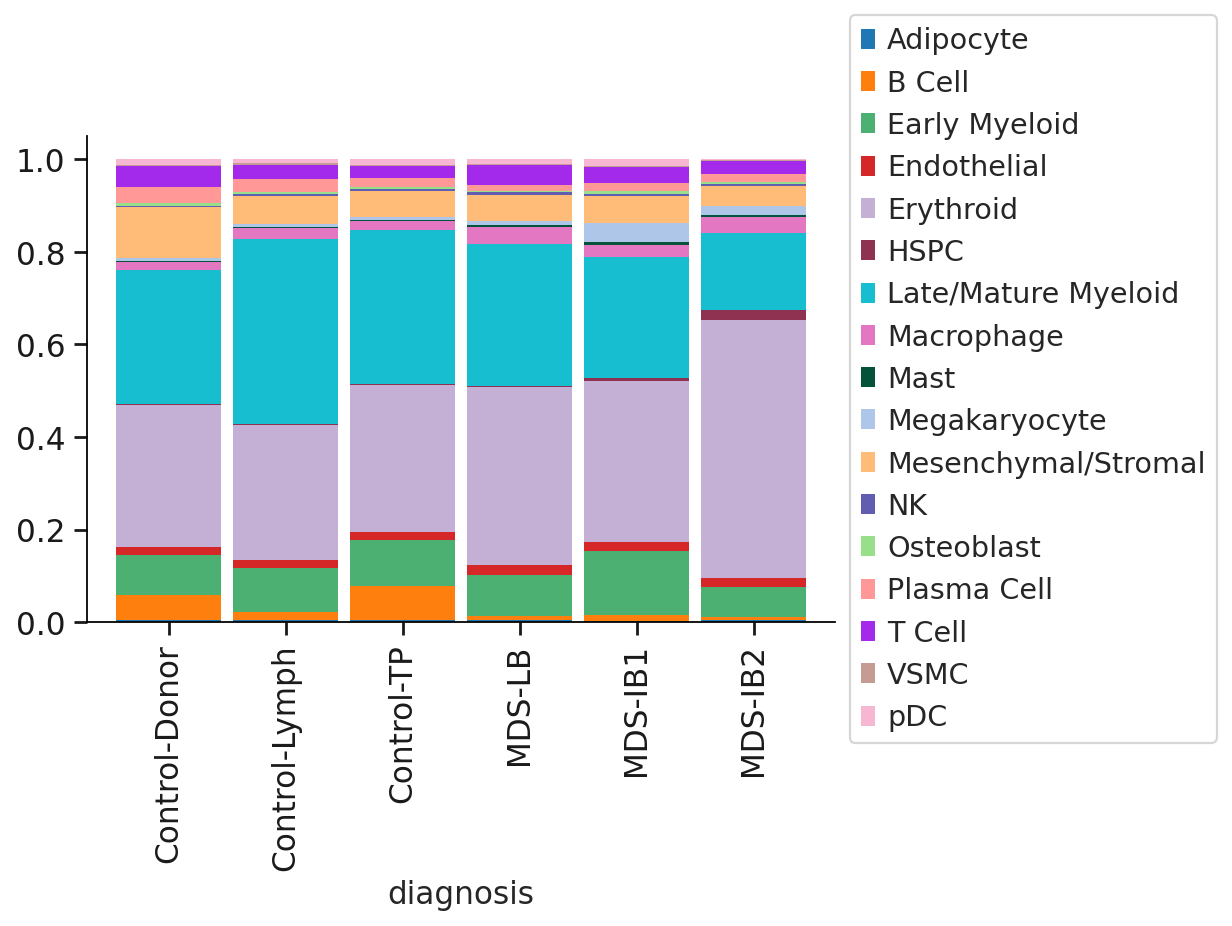

In [5]:
sc.set_figure_params(figsize=(6, 4))

f = plt.figure()
df = pd.crosstab(index=adata_xenv1.obs['diagnosis'], columns=adata_xenv1.obs['ct_general']).apply(lambda x: x/x.sum(), axis=1)
df = df.reindex(index = ['Control-Donor','Control-Lymph','Control-TP','MDS-LB','MDS-IB1','MDS-IB2'])

ct_colors = ['#1f77b4','#ff7f0e','#4db073','#d62728','#c5b0d5','#8f3251','#17becf','#e377c2','#035239','#aec7e8','#ffbb78',
 '#615db0','#98df8a','#ff9896','#a42aeb','#c49c94','#f7b6d2']

cmp = matplotlib.colors.ListedColormap(ct_colors)
g = df.plot(kind='bar', stacked=True, width = 0.9,colormap= cmp,edgecolor='none')
g.spines['top'].set_visible(False)
g.spines['right'].set_visible(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.tick_params(left=True, bottom=True)
plt.show()
